<a href="https://colab.research.google.com/github/dafandaroswa-blip/kbs-entertainment-recommender/blob/main/SmartRecommender_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SmartRecommender Final (v2) — eksperimen artikel, dataset Kaggle 2026

Notebook ini menjalankan seluruh eksperimen di bagian Method artikel: TF-IDF + cosine similarity, baseline acak dan popularitas, pembagian per franchise tanpa kebocoran, pemilihan hyperparameter di validation, serta metrik P@K, nDCG@K, ILD@K, Coverage@K (5 seed).

**Dataset (Kaggle, 2026):** film = *The Ultimate 1Million Movies Dataset (TMDB + IMDb)* (`alanvourch/tmdb-movies-daily-updates`); anime = *Anime & Manga Analytics Dataset (2026)* (`patelris/anime-and-manga-dataset-2026`). Keduanya publik, **tidak perlu login atau API key Kaggle**.

**Cara pakai:** buka di Google Colab lalu pilih menu **Runtime → Run all**. Tunggu sampai sel terakhir selesai (sekitar 10–25 menit, unduhan film ±800 MB). Hasilnya `hasil_penelitian.zip` terunduh otomatis. Kirim isi `paper_numbers.txt` ke chat. **Jangan mengisi angka dari perkiraan.**

Kalau ada sel yang error, salin pesan error-nya (baris terakhir berwarna merah) dan kirim ke chat.

## 1. Pasang pustaka dan unduh dataset

In [ ]:
!pip install -q kagglehub
import os, glob, hashlib, datetime
import kagglehub
RUN_DATE = datetime.date.today().isoformat()
print('Tanggal proses (catat sebagai tanggal akses dataset):', RUN_DATE)

Tanggal proses (catat sebagai tanggal akses dataset): 2026-11-08


In [ ]:
def get_csv(slug, prefer, avoid=()):
    try:
        folder = kagglehub.dataset_download(slug)
        csvs = [os.path.join(r, f) for r, _, fs in os.walk(folder) for f in fs if f.lower().endswith('.csv')]
        pick = [c for c in csvs if any(p in os.path.basename(c).lower() for p in prefer) and not any(a in os.path.basename(c).lower() for a in avoid)] or csvs
        path = max(pick, key=os.path.getsize)
        print('Dipakai:', path, round(os.path.getsize(path) / 1e6, 1), 'MB')
        return path
    except Exception as e:
        print('Unduhan otomatis gagal untuk', slug, '->', repr(e))
        print('Unduh file CSV-nya manual dari halaman dataset di Kaggle, lalu upload di kotak berikut.')
        from google.colab import files
        up = files.upload()
        return list(up)[0]

FILM_CSV = get_csv('alanvourch/tmdb-movies-daily-updates', prefer=['movie'])
ANIME_CSV = get_csv('patelris/anime-and-manga-dataset-2026', prefer=['anime'], avoid=['manga'])

100%|██████████| 328M/328M [00:16<00:00, 20.9MB/s]

Extracting files...


Dipakai: /root/.cache/kagglehub/datasets/alanvourch/tmdb-movies-daily-updates/versions/1055/TMDB_all_movies.csv 803.6 MB
Using Colab cache for faster access to the 'anime-and-manga-dataset-2026' dataset.
Dipakai: /kaggle/input/anime-and-manga-dataset-2026/anime_dataset.csv 17.9 MB


## 2. Kode inti eksperimen (jangan diubah kecuali diminta)

In [ ]:
# ===== Inti eksperimen: pipeline TF-IDF + cosine similarity, baseline, evaluasi bebas kebocoran =====
import re, ast, json, itertools
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit

K_LIST = [5, 10, 20]
K_MAIN = 10
SEEDS = [0, 1, 2, 3, 4]
REL_THRESHOLD = 0.5          # item dianggap relevan jika Jaccard genre >= 0.5
GRID = [dict(ngram_range=ng, min_df=md, sublinear_tf=st)
        for ng in [(1, 1), (1, 2)] for md in [1, 2] for st in [False, True]]

# ---------- deteksi kolom ----------
def guess_columns(df):
    cols = {c.lower(): c for c in df.columns}
    def first(names):
        for n in names:
            if n in cols: return cols[n]
        return None
    title = first(['title', 'name', 'movie_title', 'anime_title', 'original_title', 'movie_name', 'anime_name'])
    if title is None:
        title = next((cols[c] for c in cols if 'title' in c or c.endswith('name')), None)
    genre = first(['genres', 'genre'])
    if genre is None:
        genre = next((cols[c] for c in cols if 'genre' in c), None) or first(['themes', 'tags', 'categories'])
    skip = ['sentiment', '_id', 'id_', 'path', 'url', 'image', 'link', 'count', 'score', 'rating', 'date', 'year']
    text_cols = [cols[c] for c in cols if any(k in c for k in ['synopsis', 'summary', 'story', 'overview', 'plot', 'tagline', 'description'])
                 and not any(k in c for k in skip) and cols[c] != genre and cols[c] != title]
    pop = first(['vote_count', 'votes', 'num_votes', 'members', 'scored_by', 'popularity', 'rating_count', 'no_of_votes'])
    if pop is None:
        pop = next((cols[c] for c in cols if ('vote' in c or 'member' in c or 'count' in c) and 'average' not in c), None)
    return dict(title=title, genre=genre, text=text_cols, popularity=pop)

# ---------- penyiapan data ----------
def parse_genres(x):
    if isinstance(x, (list, tuple, set, frozenset)):
        items = list(x)
    else:
        s = str(x).strip()
        if s in ('', 'nan', 'None', '[]'): return frozenset()
        if s.startswith('['):
            try:
                items = [(d['name'] if isinstance(d, dict) else d) for d in ast.literal_eval(s)]
            except Exception:
                items = re.split(r'[,|;]', s.strip('[]'))
        else:
            items = re.split(r'[,|;]', s)
    return frozenset(str(g).strip().strip('\'"').lower() for g in items if str(g).strip())

def normalize_text(s):
    s = str(s).lower()
    s = re.sub(r'\(source:[^)]*\)', ' ', s)
    s = re.sub(r'\[written by[^\]]*\]', ' ', s)
    s = re.sub(r'<[^>]+>', ' ', s)
    s = re.sub(r'[^a-z\s]', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()

def franchise_key(title):
    t = str(title).lower()
    t = re.split(r'[:\-\u2013\u2014(]', t)[0]
    t = re.sub(r'\b(season|part|movie|film|ova|ona|special)\b.*', '', t)
    t = re.sub(r'\b(ii|iii|iv|vi|vii|viii|ix)\b\s*$', '', t.strip())
    t = re.sub(r'\d+', '', t)
    t = re.sub(r'[^a-z ]', '', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t or str(title).lower()

def prepare(df, cfg, max_items=8000):
    d = pd.DataFrame({'title': df[cfg['title']].astype(str)})
    d['genres'] = df[cfg['genre']].apply(parse_genres)
    d['text'] = df[cfg['text']].fillna('').astype(str).agg(' '.join, axis=1).map(normalize_text)
    if cfg.get('popularity') and cfg['popularity'] in df.columns:
        d['pop'] = pd.to_numeric(df[cfg['popularity']], errors='coerce').fillna(0.0)
    else:
        d['pop'] = 0.0
    n0 = int(df.attrs.get('total_rows', len(d)))
    d = d[(d['title'].str.strip() != '') & (d['text'].str.split().str.len() >= 5) & (d['genres'].map(len) > 0)]
    d = d.drop_duplicates(subset='title').reset_index(drop=True)
    n_complete = len(d)
    if max_items and len(d) > max_items:      # simpan judul terpopuler agar dua katalog sebanding dan komputasi ringan
        d = d.sort_values('pop', ascending=False, kind='stable').head(max_items).reset_index(drop=True)
    d['group'] = d['title'].map(franchise_key)
    stats = dict(raw_items=n0, complete_records=n_complete, items_used=len(d),
                 distinct_genres=len(set().union(*d['genres'])) if len(d) else 0,
                 mean_genres_per_item=float(d['genres'].map(len).mean()),
                 mean_words_per_item=float(d['text'].str.split().str.len().mean()),
                 franchise_groups=int(d['group'].nunique()),
                 largest_group_share=float(d['group'].value_counts(normalize=True).iloc[0]) if len(d) else 0.0)
    return d, stats

# ---------- relevansi & metrik ----------
def genre_matrix(genre_sets, vocab):
    G = np.zeros((len(genre_sets), len(vocab)), dtype=np.float32)
    for i, gs in enumerate(genre_sets):
        for g in gs: G[i, vocab[g]] = 1.0
    return G

def jaccard_to_all(G_ref, g_q):
    inter = G_ref @ g_q
    union = G_ref.sum(1) + g_q.sum() - inter
    return inter / np.maximum(union, 1e-9)

def query_metrics(topk, rel_all, G_ref, k_list):
    out = {}
    for K in k_list:
        idx = topk[:K]
        rel = rel_all[idx]
        out[f'P@{K}'] = float((rel >= REL_THRESHOLD).mean())
        disc = 1.0 / np.log2(np.arange(2, K + 2))
        dcg = float((rel * disc).sum())
        ideal = np.sort(rel_all)[::-1][:K]
        idcg = float((ideal * disc).sum())
        out[f'nDCG@{K}'] = dcg / idcg if idcg > 0 else 0.0
        Gs = G_ref[idx]
        inter = Gs @ Gs.T
        sz = Gs.sum(1)
        union = sz[:, None] + sz[None, :] - inter
        jac = inter / np.maximum(union, 1e-9)
        mask = ~np.eye(K, dtype=bool)
        out[f'ILD@{K}'] = float((1 - jac)[mask].mean())
    return out

def rank_topk(scores, K, exclude=None):
    s = scores.copy()
    if exclude is not None: s[exclude] = -np.inf
    top = np.argpartition(-s, K)[:K]
    return top[np.argsort(-s[top])]

# ---------- satu evaluasi ----------
def evaluate_split(ref, qry, vec_params, vocab, rng, kmax=max(K_LIST)):
    vec = TfidfVectorizer(stop_words='english', **vec_params)
    X_ref = vec.fit_transform(ref['text'])            # IDF hanya dari data referensi
    X_q = vec.transform(qry['text'])
    G_ref = genre_matrix(ref['genres'], vocab)
    G_q = genre_matrix(qry['genres'], vocab)
    pop_order = np.argsort(-ref['pop'].values, kind='stable')[:kmax]
    rows, rec_sets = [], {m: {K: set() for K in K_LIST} for m in ['content', 'random', 'popularity']}
    S = (X_q @ X_ref.T).toarray()                      # cosine (vektor sudah L2-normal)
    for qi in range(len(qry)):
        rel_all = jaccard_to_all(G_ref, G_q[qi])
        tops = {'content': rank_topk(S[qi], kmax),
                'random': rng.choice(len(ref), size=kmax, replace=False),
                'popularity': pop_order}
        for m, top in tops.items():
            r = query_metrics(top, rel_all, G_ref, K_LIST)
            r['method'] = m
            rows.append(r)
            for K in K_LIST: rec_sets[m][K].update(top[:K].tolist())
    per_q = pd.DataFrame(rows)
    res = per_q.groupby('method').mean(numeric_only=True)
    for m in res.index:
        for K in K_LIST:
            res.loc[m, f'Coverage@{K}'] = len(rec_sets[m][K]) / len(ref)
    return res

def tune(ref, seed, vocab):
    gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=seed)
    tr_i, va_i = next(gss.split(ref, groups=ref['group']))
    core, val = ref.iloc[tr_i].reset_index(drop=True), ref.iloc[va_i].reset_index(drop=True)
    best, best_score = None, -1
    for params in GRID:
        res = evaluate_split(core, val, params, vocab, np.random.default_rng(seed))
        sc = res.loc['content', f'nDCG@{K_MAIN}']
        if sc > best_score: best, best_score = params, sc
    return best, best_score

def run_dataset(d, name, seeds=SEEDS, test_size=0.2):
    vocab = {g: i for i, g in enumerate(sorted(set().union(*d['genres'])))}
    all_res, chosen = [], []
    for seed in seeds:
        gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
        r_i, q_i = next(gss.split(d, groups=d['group']))
        ref, qry = d.iloc[r_i].reset_index(drop=True), d.iloc[q_i].reset_index(drop=True)
        assert not (set(ref['group']) & set(qry['group'])), 'kebocoran: franchise sama di dua split'
        params, vscore = tune(ref, seed, vocab)
        res = evaluate_split(ref, qry, params, vocab, np.random.default_rng(1000 + seed))
        res = res.reset_index(); res['seed'] = seed; res['dataset'] = name
        all_res.append(res)
        chosen.append(dict(dataset=name, seed=seed, ngram_range=str(params['ngram_range']), min_df=params['min_df'],
                           sublinear_tf=params['sublinear_tf'], val_nDCG10=round(vscore, 4),
                           n_reference=len(ref), n_query=len(qry)))
    return pd.concat(all_res, ignore_index=True), pd.DataFrame(chosen)

def summarize(all_res):
    metrics = [c for c in all_res.columns if '@' in c]
    g = all_res.groupby(['dataset', 'method'])[metrics]
    mean, sd = g.mean(), g.std(ddof=1)
    return mean, sd


# ---------- pemuatan CSV besar dengan hemat memori ----------
def load_light(path, min_pop=None, chunksize=200000):
    head = pd.read_csv(path, nrows=0)
    cfg = guess_columns(head)
    missing = [k for k in ('title', 'genre') if not cfg[k]] + ([] if cfg['text'] else ['text'])
    if missing:
        raise ValueError(f"Kolom {missing} tidak ditemukan otomatis. Kolom yang ada: {list(head.columns)}. Isi CONFIG manual di sel berikutnya.")
    need = [c for c in [cfg['title'], cfg['genre'], cfg['popularity']] + cfg['text'] if c]
    parts, total = [], 0
    for chunk in pd.read_csv(path, usecols=need, chunksize=chunksize, low_memory=False):
        total += len(chunk)
        if min_pop is not None and cfg['popularity']:
            chunk = chunk[pd.to_numeric(chunk[cfg['popularity']], errors='coerce').fillna(0) >= min_pop]
        parts.append(chunk)
    df = pd.concat(parts, ignore_index=True)
    df.attrs['total_rows'] = total
    return df, cfg


## 3. Muat data dan cek kolom

Film dimuat hemat memori (hanya kolom yang perlu, dan hanya film dengan minimal 50 vote). Perhatikan hasil tebakan kolom di bawah; kalau ada yang salah, ubah `CONFIG`.

In [ ]:
MAX_ITEMS = 8000   # judul terpopuler yang dipakai per katalog
film_raw, film_cfg = load_light(FILM_CSV, min_pop=50)
anime_raw, anime_cfg = load_light(ANIME_CSV)
CONFIG = {'film': film_cfg, 'anime': anime_cfg}
# Contoh koreksi manual bila perlu:
# CONFIG['anime']['text'] = ['synopsis']
# CONFIG['anime']['genre'] = 'genres'
for k, v in CONFIG.items(): print(k, '->', v)
print('Baris film terbaca (setelah filter vote):', len(film_raw), '| total baris file film:', film_raw.attrs['total_rows'])
print('Baris anime terbaca:', len(anime_raw))

film -> {'title': 'title', 'genre': 'genres', 'text': ['overview', 'tagline'], 'popularity': 'vote_count'}
anime -> {'title': 'title', 'genre': 'genres', 'text': ['synopsis'], 'popularity': 'members'}
Baris film terbaca (setelah filter vote): 36580 | total baris file film: 1271935
Baris anime terbaca: 30075


## 4. Penyiapan data dan statistik dataset (untuk Tabel 1)

In [ ]:
def md5(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''): h.update(b)
    return h.hexdigest()

raws = {'film': (film_raw, FILM_CSV), 'anime': (anime_raw, ANIME_CSV)}
data, stats = {}, {}
for name, (raw, path) in raws.items():
    cfg = CONFIG[name]
    bad = [c for c in cfg['text'] if set(re.split('[^a-z]+', c.lower())) & {'genre', 'genres', 'tag', 'tags', 'theme', 'themes', 'category', 'categories'}]
    assert not bad, f'Kolom teks {bad} berisi label genre/tag: ini menyebabkan kebocoran. Ubah CONFIG.'
    assert cfg['genre'] not in cfg['text'], 'Kolom genre tidak boleh dipakai sebagai fitur teks.'
    data[name], stats[name] = prepare(raw, cfg, max_items=MAX_ITEMS)
    stats[name].update(file=os.path.basename(path), size_mb=round(os.path.getsize(path) / 1e6, 1), md5=md5(path), accessed=RUN_DATE,
                       text_fields=', '.join(cfg['text']), genre_field=cfg['genre'], popularity_field=cfg['popularity'])
    if stats[name]['largest_group_share'] > 0.05:
        print('PERINGATAN: satu grup franchise terlalu besar di', name, '-> cek fungsi franchise_key')
stats_df = pd.DataFrame(stats).T
stats_df.to_csv('dataset_stats.csv')
stats_df.T

,film,anime
raw_items,1271935,30075
complete_records,34007,20021
items_used,8000,8000
distinct_genres,19,21
mean_genres_per_item,2.624875,2.28325
mean_words_per_item,52.813625,101.431875
franchise_groups,7140,5267
largest_group_share,0.002125,0.00675
file,TMDB_all_movies.csv,anime_dataset.csv
size_mb,803.6,17.9


## 5. Jalankan eksperimen (5 seed; bisa beberapa menit)

In [ ]:
results, chosen = [], []
for name, d in data.items():
    r, c = run_dataset(d, name)
    results.append(r); chosen.append(c)
    print(name, 'selesai')
all_res = pd.concat(results, ignore_index=True)
hp = pd.concat(chosen, ignore_index=True)
all_res.to_csv('per_seed_results.csv', index=False)
hp.to_csv('hyperparameters.csv', index=False)
hp

film selesai
anime selesai


,dataset,seed,ngram_range,min_df,sublinear_tf,val_nDCG10,n_reference,n_query
0,film,0,"(1, 1)",1,True,0.3006,6404,1596
1,film,1,"(1, 1)",1,True,0.3000,6411,1589
2,film,2,"(1, 1)",1,True,0.3095,6406,1594
3,film,3,"(1, 1)",1,True,0.2981,6384,1616
4,film,4,"(1, 1)",1,True,0.3086,6401,1599
5,anime,0,"(1, 2)",1,True,0.2789,6343,1657
6,anime,1,"(1, 2)",1,True,0.3047,6360,1640
7,anime,2,"(1, 1)",1,True,0.3190,6482,1518
8,anime,3,"(1, 2)",1,True,0.3131,6306,1694
9,anime,4,"(1, 1)",1,True,0.2910,6483,1517


## 6. Ringkasan hasil (untuk Tabel 2) dan file angka untuk dikirim ke chat

In [ ]:
mean, sd = summarize(all_res)
show = ['P@10', 'nDCG@10', 'ILD@10', 'Coverage@10']
summary = (mean[show].round(3).astype(str) + ' ± ' + sd[show].round(3).astype(str))
summary.to_csv('results_summary.csv')
print(summary)
lines = ['DATASET STATS'] + [f'{k}: {v}' for k, v in stats.items()] + ['', 'HYPERPARAMETER TERPILIH'] + hp.astype(str).agg(' | '.join, axis=1).tolist() + ['', 'HASIL (rata-rata ± SD, 5 seed)']
for (ds, m), row in mean.iterrows():
    lines.append(f'{ds} | {m} | ' + ' | '.join(f'{c}={row[c]:.3f}±{sd.loc[(ds, m), c]:.3f}' for c in mean.columns))
lines += ['', 'JUMLAH SEED DI MANA CONTENT > BASELINE']
for ds in all_res['dataset'].unique():
    sub = all_res[all_res['dataset'] == ds]
    for base in ['random', 'popularity']:
        for met in show:
            c = sub[sub.method == 'content'].set_index('seed')[met]; b = sub[sub.method == base].set_index('seed')[met]
            lines.append(f'{ds} | content > {base} | {met}: {(c > b).sum()}/{len(c)}')
open('paper_numbers.txt', 'w').write('\n'.join(lines))
print('\n'.join(lines))

                             P@10        nDCG@10         ILD@10    Coverage@10
dataset method                                                                
anime   content      0.277 ± 0.01   0.31 ± 0.006  0.764 ± 0.005  0.785 ± 0.028
        popularity  0.079 ± 0.012  0.129 ± 0.009  0.727 ± 0.029    0.002 ± 0.0
        random      0.093 ± 0.003  0.137 ± 0.003  0.866 ± 0.002  0.918 ± 0.013
film    content     0.262 ± 0.001  0.305 ± 0.003  0.777 ± 0.002  0.807 ± 0.004
        popularity  0.105 ± 0.012  0.163 ± 0.009  0.772 ± 0.024    0.002 ± 0.0
        random      0.103 ± 0.005  0.163 ± 0.003  0.842 ± 0.001  0.917 ± 0.003
DATASET STATS
film: {'raw_items': 1271935, 'complete_records': 34007, 'items_used': 8000, 'distinct_genres': 19, 'mean_genres_per_item': 2.624875, 'mean_words_per_item': 52.813625, 'franchise_groups': 7140, 'largest_group_share': 0.002125, 'file': 'TMDB_all_movies.csv', 'size_mb': 803.6, 'md5': 'de09aa3e206380ba115ff079ff33be43', 'accessed': '2026-11-08', 'text_fiel

## 7. Gambar (300 dpi, tanpa judul di atas, ada legenda dan label sumbu — sesuai template)

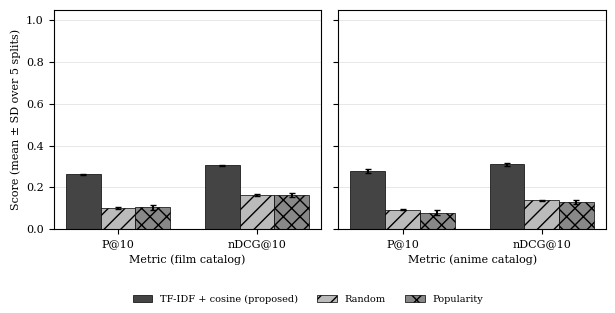

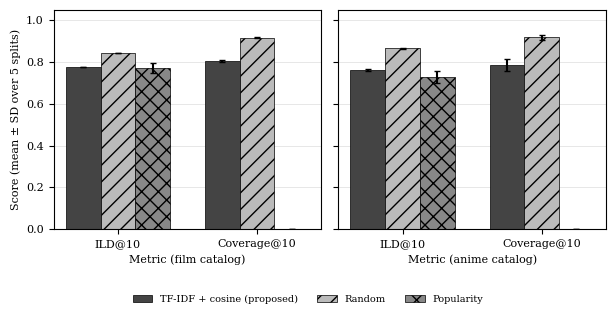

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 8})
methods = [('content', 'TF-IDF + cosine (proposed)', '#444444', ''), ('random', 'Random', '#BBBBBB', '//'), ('popularity', 'Popularity', '#888888', 'xx')]
def panel_fig(metrics, fname):
    ds_list = list(data.keys())
    fig, axes = plt.subplots(1, len(ds_list), figsize=(6.2, 3.1), sharey=True)
    for ax, ds in zip(np.atleast_1d(axes), ds_list):
        w = 0.25
        for j, (m, lab, col, hatch) in enumerate(methods):
            vals = [mean.loc[(ds, m), x] for x in metrics]; errs = [sd.loc[(ds, m), x] for x in metrics]
            ax.bar(np.arange(len(metrics)) + (j - 1) * w, vals, w, yerr=errs, capsize=2, color=col, hatch=hatch, edgecolor='black', linewidth=0.5, label=lab)
        ax.set_xticks(range(len(metrics))); ax.set_xticklabels(metrics); ax.set_xlabel(f'Metric ({ds} catalog)'); ax.set_ylim(0, 1.05)
        ax.grid(axis='y', color='#DDDDDD', linewidth=0.5); ax.set_axisbelow(True)
    np.atleast_1d(axes)[0].set_ylabel('Score (mean ± SD over 5 splits)')
    h, l = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=3, fontsize=7, frameon=False)
    fig.tight_layout(rect=[0, 0.1, 1, 1]); fig.savefig(fname, dpi=300); plt.show()
panel_fig(['P@10', 'nDCG@10'], 'figure2_accuracy.png')
panel_fig(['ILD@10', 'Coverage@10'], 'figure3_diversity_coverage.png')

In [ ]:
import zipfile
with zipfile.ZipFile('hasil_penelitian.zip', 'w') as z:
    for f in ['dataset_stats.csv', 'per_seed_results.csv', 'hyperparameters.csv', 'results_summary.csv', 'paper_numbers.txt', 'figure2_accuracy.png', 'figure3_diversity_coverage.png']:
        z.write(f)
try:
    from google.colab import files
    files.download('hasil_penelitian.zip')
except ImportError:
    print('Zip tersimpan: hasil_penelitian.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>